# Iris dataset task — multi-class classification

**Goal:** classify iris flowers into 3 species (setosa, versicolor, virginica) from 4 measurements.

This is the **multi-class** version of the confusion matrix (like the *ball colours* notes from class): with 3 classes the confusion matrix is 3×3, and precision/recall are calculated **per class**.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, roc_auc_score
iris = load_iris(as_frame=True)
df = iris.frame.copy(); df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
print(df.shape); df.head()

(150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 1. Explore

In [2]:
print(df['species'].value_counts())
df.groupby('species').mean(numeric_only=True).round(2)

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
species,,,,,
setosa,5.01,3.43,1.46,0.25,0.0
versicolor,5.94,2.77,4.26,1.33,1.0
virginica,6.59,2.97,5.55,2.03,2.0


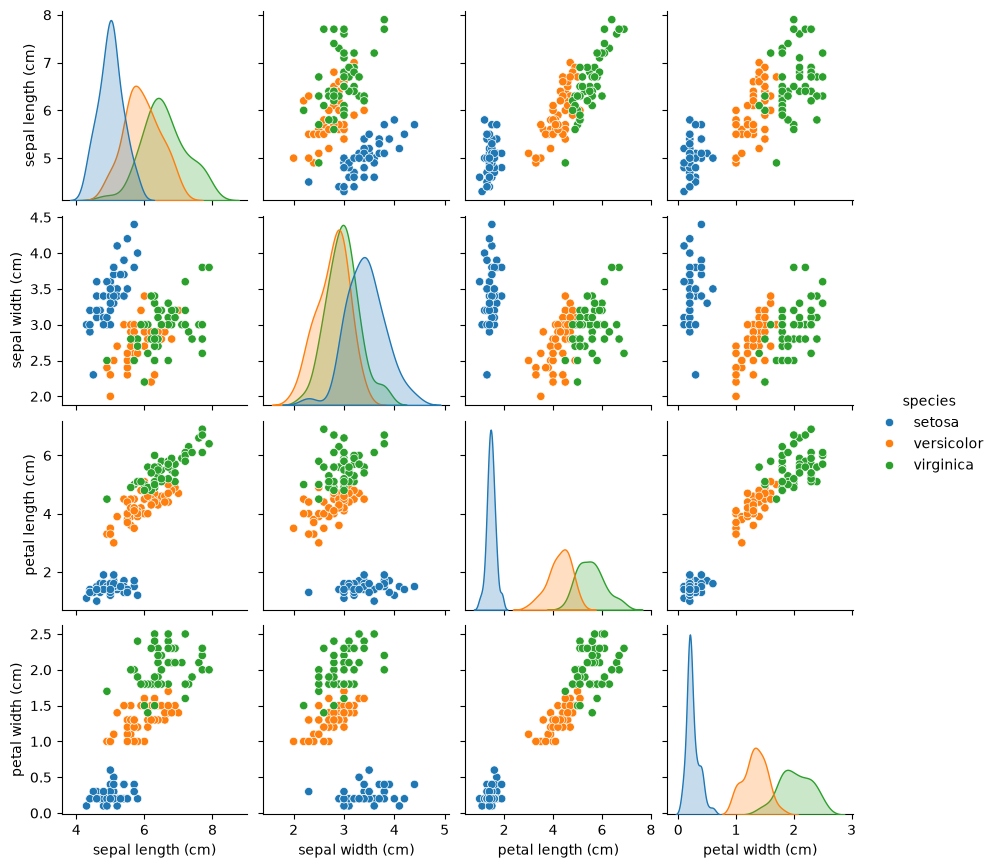

In [3]:
sns.pairplot(df.drop(columns='target'), hue='species', height=2.2); plt.show()

**Observation to look for:** petal length and petal width separate *setosa* completely; *versicolor* and *virginica* overlap a little — that is where mistakes will happen.

## 2. Split and train three models

In [4]:
X = df[iris.feature_names]; y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'K-Nearest Neighbours (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
}
for name, m in models.items():
    m.fit(X_train, y_train); pred = m.predict(X_test)
    print(f'===== {name}  accuracy = {accuracy_score(y_test, pred):.3f}')
    print(classification_report(y_test, pred, target_names=iris.target_names, digits=3))

===== Logistic Regression  accuracy = 0.911
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.824     0.933     0.875        15
   virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45

===== K-Nearest Neighbours (k=5)  accuracy = 0.911
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.789     1.000     0.882        15
   virginica      1.000     0.733     0.846        15

    accuracy                          0.911        45
   macro avg      0.930     0.911     0.910        45
weighted avg      0.930     0.911     0.910        45

===== Decision Tree  accuracy = 0.978


              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     0.933     0.966        15
   virginica      0.938     1.000     0.968        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45



## 3. The 3×3 confusion matrix
- Rows = the **true** species, columns = the **predicted** species.
- The **diagonal** = correct predictions. Anything off the diagonal is a mistake, and it tells you *which* species was confused with which.
- **Precision for a class** = correct predictions of that class ÷ everything predicted as that class (read down the column).
- **Recall for a class** = correct predictions of that class ÷ everything that truly is that class (read across the row).

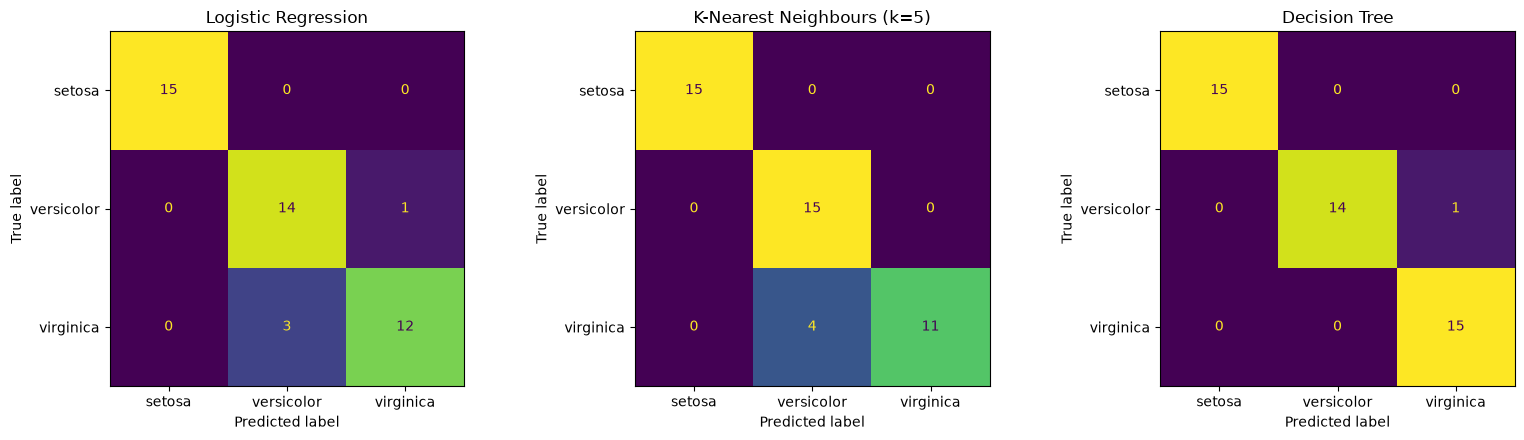

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)), display_labels=iris.target_names).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

In [6]:
# Working precision and recall out by hand for one model, to show where the numbers come from
cm = confusion_matrix(y_test, models['Logistic Regression'].predict(X_test))
for i, name in enumerate(iris.target_names):
    tp = cm[i, i]; precision = tp / cm[:, i].sum(); recall = tp / cm[i, :].sum()
    print(f'{name:12s} TP={tp:2d}  precision={precision:.3f}  recall={recall:.3f}')

setosa       TP=15  precision=1.000  recall=1.000
versicolor   TP=14  precision=0.824  recall=0.933
virginica    TP=12  precision=0.923  recall=0.800


## 4. Multi-class ROC AUC (one-vs-rest) and cross-validation

In [7]:
for name, m in models.items():
    auc = roc_auc_score(y_test, m.predict_proba(X_test), multi_class='ovr')
    cv = cross_val_score(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42))
    print(f'{name:28s} one-vs-rest AUC = {auc:.3f}   5-fold CV accuracy = {cv.mean():.3f} ± {cv.std():.3f}')

Logistic Regression          one-vs-rest AUC = 0.996   5-fold CV accuracy = 0.953 ± 0.045


K-Nearest Neighbours (k=5)   one-vs-rest AUC = 0.989   5-fold CV accuracy = 0.973 ± 0.025


Decision Tree                one-vs-rest AUC = 0.990   5-fold CV accuracy = 0.960 ± 0.025


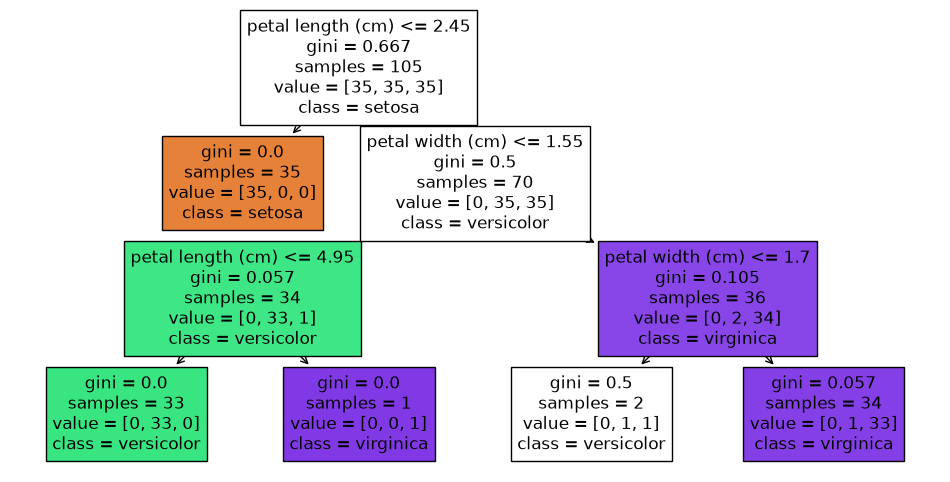

In [8]:
plt.figure(figsize=(12, 6))
plot_tree(models['Decision Tree'], feature_names=iris.feature_names, class_names=iris.target_names, filled=True); plt.show()

## 6. Conclusion
- All three models classify iris species well: test accuracy **91 % (Logistic Regression, KNN) and 98 % (Decision Tree)**; 5-fold cross-validation **95–97 %**; one-vs-rest AUC ≈ **0.99**.
- **Setosa is always classified perfectly** (precision = recall = 1.00) because its petals are much smaller — it is linearly separable.
- **All mistakes are between versicolor and virginica**, whose petal sizes overlap (see the pair plot). In the Logistic Regression matrix, 3 virginica were predicted as versicolor (virginica recall 0.80) and 1 versicolor as virginica.
- The 3×3 confusion matrix shows *which* classes are confused — something a single accuracy number cannot show. Per-class precision is read down a column, per-class recall across a row.
- The Decision Tree's 98 % on one 45-flower test set is partly luck: cross-validation (≈96 %) is the more trustworthy estimate.